In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

# Lab 1

## 1A

For our single day I will assume our mean is 5, and that our source emissions came out to 9.

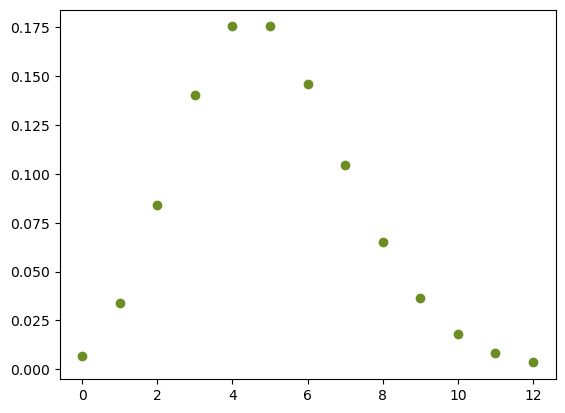

In [2]:
mu = 5
x = np.arange(stats.poisson.ppf(0.001, mu), stats.poisson.ppf(.999, mu))
day_one = stats.poisson.pmf(x, mu)
dx = x[1] - x[0]
fig, ax = plt.subplots()

day_two = np.convolve(day_one, day_one, mode = 'full') * dx
x_two = 2*x[0] + np.arange(len(day_two))
day_three = np.convolve(day_two, day_one, mode = 'full')
x_three = 3*x[0] + np.arange(len(day_three))
day_four = np.convolve(day_three, day_one, mode = 'full')
x_four = 4*x[0] + np.arange(len(day_four))
day_five = np.convolve(day_four, day_one, mode = 'full')
x_five = 5*x[0] + np.arange(len(day_five))
ax.scatter(x, day_one, color = 'olivedrab')
    # ax[i].vlines(x, 0, stats.poisson.pmf(x, mu), colors='olivedrab', lw=5, alpha=0.5)

plt.show()


Above we have the distribution for one day.

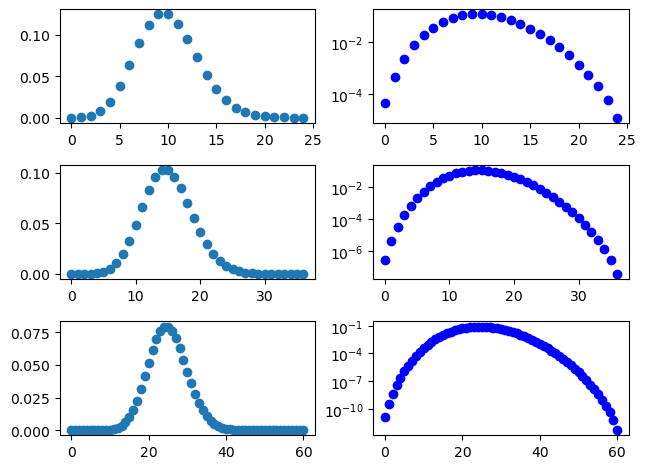

In [3]:
fig, ax = plt.subplots(3, 2)
ax[0, 0].scatter(x_two, day_two)
ax[1, 0].scatter(x_three, day_three)
ax[2, 0].scatter(x_five, day_five)
ax[0, 1].semilogy(x_two, day_two, 'bo')
ax[1, 1].semilogy(x_three, day_three, 'bo')
ax[2, 1].semilogy(x_five, day_five, 'bo')
plt.tight_layout()
plt.show()

We can see our distributions are getting a little tighter around the mean, or in this case the sum of the means.

## 1B

The semilog plot clearly demonstrates the non-gaussian nature of the distribution.

## 1C

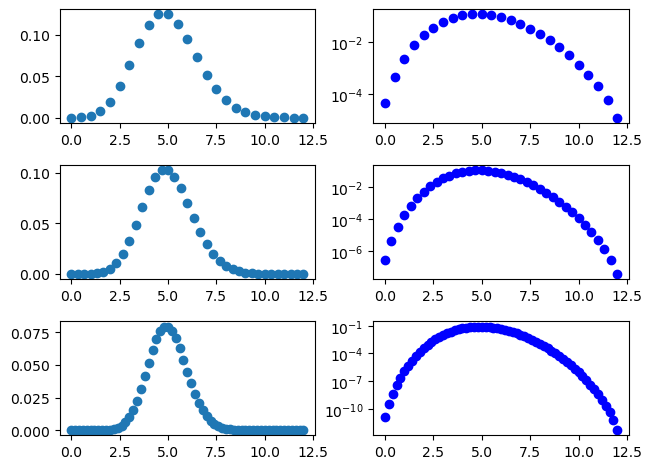

In [4]:
fig, ax = plt.subplots(3, 2)
ax[0, 0].scatter(x_two / 2, day_two)
ax[1, 0].scatter(x_three / 3, day_three)
ax[2, 0].scatter(x_five / 5, day_five)
ax[0, 1].semilogy(x_two / 2, day_two, 'bo')
ax[1, 1].semilogy(x_three / 3, day_three, 'bo')
ax[2, 1].semilogy(x_five / 5, day_five, 'bo')
plt.tight_layout()
plt.show()



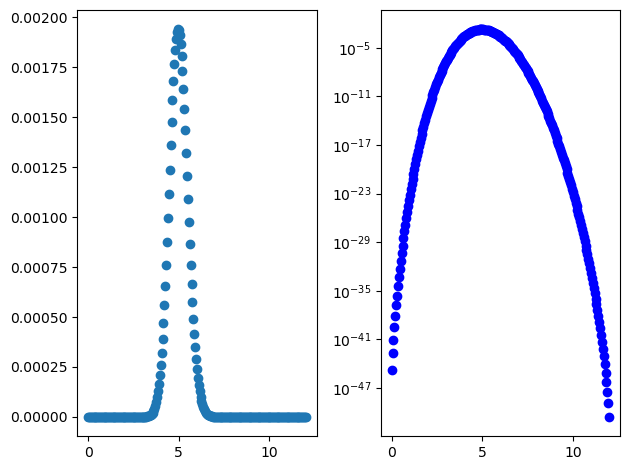

In [5]:

for i in range(15):
    day_five = np.convolve(day_five, day_one, mode = 'full')

x_twenty = 20 * x[0] + np.arange(len(day_five))
fig, ax = plt.subplots(1, 2)
ax[0].scatter(x_twenty / 20, day_five / 20)
ax[1].semilogy(x_twenty / 20, day_five / 20, 'bo')
plt.tight_layout()
plt.show()

In the above we can see the distribution slowly shifting towards Gaussian after averaging 20.

## 1D

Let's use our twenty day distribution from above.

In [6]:
signal = np.sum(day_five) - np.sum(day_five[0:179])
print(len(day_five))
print(x_twenty[180] / 20)
print(day_five[180] / 20)
print(np.sum(day_five))
print(signal)
sigma = stats.norm.ppf(signal)
print(sigma)

241
9.0
3.073872575992119e-16
0.9603880618493061
2.4424906541753444e-14
-7.53495636943005


In the above I have a few things printed for my own sake and the sake of clarity. I was having troubl previously because the initial distribution wasn't complete and didn't *perfectly* sum to 1, and with repeated convolutions that slowly drifts down away from 1. Instead of the typical 1 - cdf I have the full cdf - cdf(point of interest), which gives an extremely small probability, which makes sense based on the graph above. This translates to ~7.5 sigma, which I would be happy to publish.

## 2A

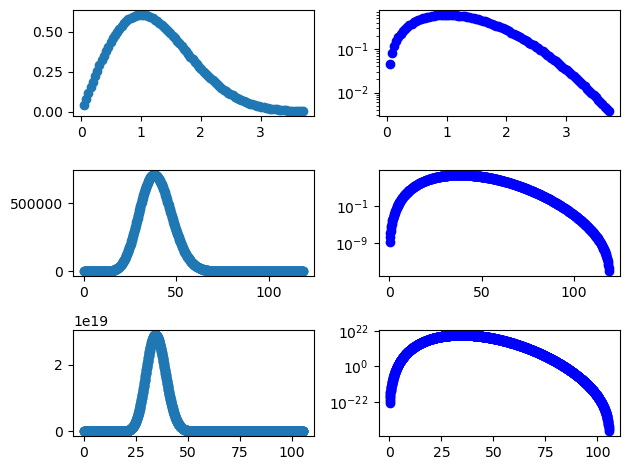

In [7]:
x_ray = np.linspace(stats.rayleigh.ppf(0.001), stats.rayleigh.ppf(0.999), 100)
rayleigh = stats.rayleigh.pdf(x_ray, loc = 0, scale = 1)
rayleigh_2 = rayleigh
for i in range(5):
    rayleigh_2 = np.convolve(rayleigh_2, rayleigh, mode = 'full')
x_ray2 = x_ray[0] + np.arange(len(rayleigh_2)) / 5
rayleigh_3 = rayleigh
for i in range(15):
    rayleigh_3 = np.convolve(rayleigh_3, rayleigh, mode = 'full')
x_ray3 = x_ray[0] + np.arange(len(rayleigh_3)) / 15

fig, ax = plt.subplots(3, 2)
ax[0, 0].scatter(x_ray, rayleigh)
ax[0,1].semilogy(x_ray, rayleigh, 'bo')
ax[1, 0].scatter(x_ray2, rayleigh_2 / 5)
ax[1, 1].semilogy(x_ray2, rayleigh_2 / 5, 'bo')
ax[2, 0].scatter(x_ray3, rayleigh_3 / 15)
ax[2, 1].semilogy(x_ray3, rayleigh_3 / 15, 'bo')
plt.tight_layout()
plt.show()


## 2B

Frankly I have no clue why the numbers get so big on the last convolution. Regardless, despite the regular plot *seeming* Gaussian the semilogy plot really doesn't make it seem like it's going to become Gaussian any time soon.

## 3A

I will use a Gaussian with a std of .25 and say I got a reading of 1.25.

In [8]:
ligo = stats.norm.sf(1.25, loc = 0, scale = .25)
print(ligo)
sigma = stats.norm.ppf(ligo)
print(sigma)

2.866515718791933e-07
-5.000000000000001


5 is just barely enough! Boy, I hope it holds up in the next problem...

## 3B

I think the crux of the argument here is that when you look for a rare event a large number of times, finding it once in 10,000 trials becomes a much less powerful statement.


In [9]:
pixels = np.zeros((10000, 1000))
for i in range(10000):
    pixels[i] = stats.norm.rvs(loc = 0, scale = 0.25, size = 1000)
pixelavg = np.sum(pixels, axis = 0) / 10000

pixels_success = pixels >= 1.25
pixels_success = pixels_success[pixels_success == True]
print(pixels_success)

[]


I ran the above cell 20 times and didn't get a single instance without at least one "success." That to me at least demonstrates the principle, but I will try to state the issue more formally.

Instead of the probability that a single pixel had the background produce a 1.25 reading, let's think about the probability that *one or more of the pixels* had the background produce a 1.25. 

***What is the probability that at least one pixel detected a background signal that is 1.25 or higher?***

With n dice, the probability that at least one produces a six is 1 - (the probability of not rolling a six)^n. I think I can use that same method here. I will use our previous value "ligo" to perform this.

## 3C

In [10]:
one_or_more = 1 - (1 - ligo)**10000
print(one_or_more)
newsig = stats.norm.isf(one_or_more)
print(newsig)

0.0028624115955605545
2.763139849407715


Uh-oh! Our 5 sigma turned into a 2.76. My PI is gonna kill me!

As a side note, your announcement on canvas was extremely helpful and led me to overcome the mental block I had regarding these problems. Thanks!

## 4A

I think the way that I set up 3A (a little contrived, sure) gives the answer to this one: 1.25.

## 4B

In [24]:
fivesigma = 1 - ((1 - (stats.norm.sf(5)))**(1/10000))
# just reverting the equation that got me the previous, replacing one_or_more with 5
print(fivesigma)
signalrequired = .25 * stats.norm.isf(fivesigma)
print(signalrequired)

2.8665181339704304e-11
1.6376343717229138


1.64 is a little lower than I expected, honestly, but not ridiculous I suppose. Running it back through the other way works out.

## 4C

Let's do a little trials testing and such.

In [49]:
def trials(m):
    one_or_more = 1 - (1 - ligo)**m
    newsig = stats.norm.isf(one_or_more)
    signalrequired = .25 * stats.norm.isf(1 - ((1 - (stats.norm.sf(5)))**(1/m)))
    print(f'Probability: {one_or_more} \nStandard Deviations: {np.round(newsig, decimals = 3)} \nSignal Needed: {np.round(signalrequired, decimals = 4)}')
    return

factors = np.array([1, 10, 100, 1000, 10000, 100000, 1000000])

print(trials(factors))

Probability: [2.86651572e-07 2.86651202e-06 2.86647505e-05 2.86610532e-04
 2.86241160e-03 2.82582132e-02 2.49226757e-01] 
Standard Deviations: [5.    4.536 4.024 3.444 2.763 1.907 0.677] 
Signal Needed: [1.25   1.3567 1.4561 1.5494 1.6376 1.7215 1.8017]
None


## 4D

(I am including the discussion for 4C here)

The falloff is much less sharp than I expected. Based on our distribution, which is not Gaussian but instead a power of Gaussians, I would say that the lack of sensitivity required is due to the exponential factor and our requirement of five sigma to begin with. Raising a number very close to one (due to our five sigma requirement) to a large power doesn't get it down from one very quickly. Even with a million pixels we just need a 1.8; not even 8 sigma!

Thanks again for all your help. Next lab I will come in more prepared and with better code knowledge!